In [7]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
jam = rng.uniform(1,9,size=60)
nilai = 35 + 5 * jam + rng.normal(
    loc=0,scale=6,size=60)
df = pd.DataFrame({"jam_belajar": jam,
                   "nilai_ujian": nilai})

In [8]:
df.head()

,jam_belajar,nilai_ujian
0,7.191648,65.763255
1,4.511028,63.364808
2,7.868783,64.246698
3,6.578944,65.885411
4,1.753419,44.743612


In [9]:
df.shape

(60, 2)

In [10]:
df.isna().sum()

,0
jam_belajar,0
nilai_ujian,0


In [11]:
df.describe()

,jam_belajar,nilai_ujian
count,60.000000,60.000000
mean,5.158475,59.549841
std,2.268995,12.131672
min,1.058898,29.930568
25%,3.184446,50.334266
50%,5.121159,60.134906
75%,7.200503,67.910802
max,8.804979,82.542228


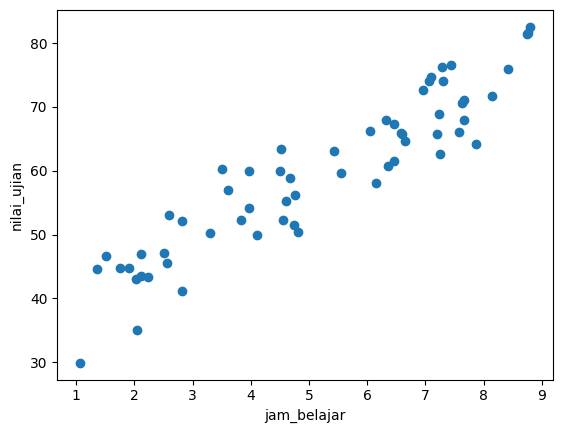

In [14]:
import matplotlib.pyplot as plt


plt.scatter(df['jam_belajar'],
df['nilai_ujian'])
plt.xlabel('jam_belajar')
plt.ylabel('nilai_ujian')
plt.show()

In [17]:
from sklearn.model_selection import train_test_split

X = df[["jam_belajar"]]
y = df[["nilai_ujian"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [19]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [20]:
b0 = float(model.intercept_)
b1 = float(model.coef_[0])
print(f"model colab: nilai_prediksi ="
f"{b0:.3f} + ({b1:.3f}) x jam_belajar")

model colab: nilai_prediksi =34.841 + (4.839) x jam_belajar


/tmp/ipykernel_5188/2981358724.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  b0 = float(model.intercept_)
/tmp/ipykernel_5188/2981358724.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  b1 = float(model.coef_[0])


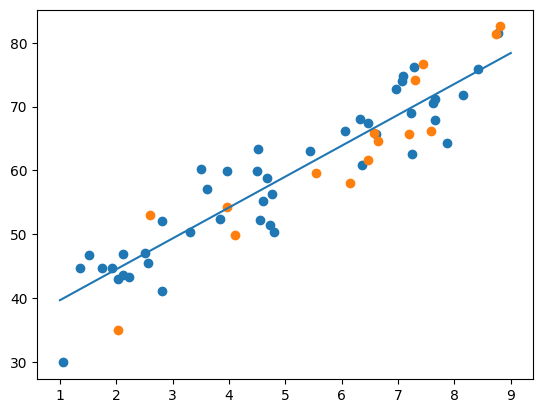

In [26]:
x_grid = pd.DataFrame(
    {"jam_belajar":np.linspace(1,9,100)})
y_grid = model.predict(x_grid)
plt.scatter(X_train["jam_belajar"],y_train)
plt.scatter(X_test["jam_belajar"],y_test)
plt.plot(x_grid["jam_belajar"],y_grid)

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_test = model.predict(X_test)
mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(
    mean_squared_error(y_test, pred_test))
r2 = r2_score(y_test, pred_test)
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print (f"R2: {r2:.3f}")

MAE: 4.324
RMSE: 4.884
R2: 0.839
